# CAES Mini-Project: Variant 1b System Design and Simulation

Compressed Air Energy Storage (CAES) stores electricity during off-peak hours by compressing ambient air into a storage reservoir. During discharge, the compressed air is extracted, heated via a combustor, and expanded through a turbine to generate electricity. 

## Variant 1b Description

**Variant 1b** models a single-stage, non-adiabatic CAES plant with a constant-pressure reservoir:
* **Charge:** Ambient air is compressed in a single-stage compressor directly to the storage pressure $P_{\text{max}}$. The heat of compression is removed via a water cooler and rejected to ambient (no thermal storage), bringing the air towards ambient temperature before storage.
* **Storage:** The reservoir operates under constant pressure ($P_{\text{max}} = 16\text{ bar}$) with a variable volume. The stored air equilibrates thermally to ambient temperature $T_0$ before and during discharge.
* **Discharge:** Air leaves the store at a constant inlet pressure of 16 bar (quasi-steady expansion). A fuel combustor heats the air from near ambient conditions up to the turbine inlet temperature ($550^\circ\text{C}$) before it expands across a single turbine stage to ambient pressure.

## System Specifications & Given Parameters

| Category | Parameter | Symbol | Value | Unit / Description |
|---|---|---|---|---|
| **Fluid Properties** | Working fluid | — | Air | Real-gas properties via CoolProp (`"Air"`) |
| **Ambient Conditions** | Ambient temperature | $T_0$ | 15 (288.15) | °C (K) |
| | Ambient pressure | $P_0$ | 1.013 | bar (compressor inlet / turbine exhaust) |
| **Storage Conditions** | Storage / max pressure | $P_{\text{max}}$ | 16 | bar (held constant during operation) |
| | Reservoir thermal state | $T_{\text{res}}$ | 15 (288.15) | °C (assumed returns and remains at $T_0$) |
| **Operating Targets** | Discharge shaft power | $P_{\text{shaft}}$ | 1 | MW |
| | Discharge duration | $\Delta t_{\text{dis}}$ | 4 | h (delivers 4 MWh per cycle) |
| | Charge duration | $\Delta t_{\text{ch}}$ | 4 | h (governs charge mass flow rate) |
| **Component Efficiencies** | Compressor isentropic efficiency | $\eta_{\text{is,c}}$ | 0.85 | Single stage |
| | Turbine isentropic efficiency | $\eta_{\text{is,t}}$ | 0.88 | Single stage |
| | Mechanical / generator efficiency | $\eta_{\text{mech}}$ | 0.98 | Shaft transmission / generator conversion |
| **Thermal Parameters** | Cooler pinch | $\Delta T_{\text{pinch}}$ | 10 | K (air cooled towards $T_0 + 10\text{ K}$) |
| | Turbine inlet temperature | TIT | 550 (823.15) | °C (K), achieved via direct heat addition |
| | Reference fuel-to-electricity efficiency | $\eta_f$ | 0.40 | Metric weighting factor for fuel input |

## Design and Simulation Tasks

The project workflow for Variant 1b consists of two phases:

1. **Design Mode:**
   * Size the single-stage compressor and turbine for the specified 1 MW / 4 h delivery target.
   * Size the water cooler heat-exchanger area ($A$) based on the aftercooling duty and 10 K pinch.
   * Size the required constant-pressure storage volume ($V$) needed to store the total cycle air mass.

2. **Simulation Mode:**
   * Simulate a full charge and discharge cycle under quasi-steady constant-pressure operation.
   * Compute the overall round-trip efficiency ($\eta$), where fuel is converted to its electrical equivalent:
     $$\eta = \frac{W_{\text{turbine}}}{W_{\text{compressor}} + \eta_f \cdot Q_{\text{combustion}}}, \qquad \eta_f = 0.40$$
   * Evaluate the energy balance, the electrical vs. fuel input split ($W_{\text{compressor}}$ vs. $Q_{\text{combustion}}$), and the peak compressor discharge temperature.
   * Provide at least one quantified performance improvement proposal and benchmark the storage volume and efficiency against the sliding-pressure variant (1a).

Here are some sources i used to return to later (soso)

Return to Gas Turbines EENG4 S8 for compressor eq and details (soso)

Paper on which sile will the pinch temp be occuring based on the Cc and Ch (LMTD) method. https://sci-hub.fr/10.1016/B978-008042839-0/50008-2 (soso)

Also return to EENG3 S6 Lec 4 for counter flow details and eq (soso)

The following section defines the imports used in the code

In [130]:
# --- imports ---
from pathlib import Path
import sys

for root in (Path.cwd(), *Path.cwd().parents):
    for package_root in (root, root / "caldis-0.3.0"):
        if (package_root / "caldis" / "__init__.py").is_file():
            sys.path.insert(0, str(package_root))
            break
    else:
        continue
    break

import numpy as np
from CoolProp.CoolProp import PropsSI

import caldis
from caldis.core.system import System
from caldis.components import FluidBoundary, Compressor, SizingHX, CombustionChamber, Turbine
from caldis.components.vessels.tank import TankConstP

from caldis.fluids import CoolPropBackend

from caldis.solvers import dynamic, solve, simulate
#from caldis.solvers import solve, simulate


### CAES Variant 1b — System Layout & Flow

#### 1. Charge Phase
| Step | Component | Flow / Working Fluid | Energy / Secondary Streams |
|:---:|:---|:---|:---|
| **1** | **Ambient Intake** | Air at ambient ($T_0 = 15^\circ\text{C},\; P_0 = 1.013\text{ bar}$) | — |
| | $\Downarrow$ | *Suction line* | |
| **2** | **Compressor** | Single-stage compression $\rightarrow P_{\text{max}} = 16\text{ bar}$ | $\longleftarrow$ **Compressor work (elec. in)** |
| | $\Downarrow$ | *Hot compressed air* | |
| **3** | **Cooler (water)** | Cooled to $T_0 + 10\text{ K} = 25^\circ\text{C}$ | $\longrightarrow$ **Rejected heat (not recovered)** |
| | $\Downarrow$ | *Cooled air at $16\text{ bar}$* | |

#### 2. Storage Phase
| Component | Operating State & Storage Characteristics |
|:---|:---|
| **Air Storage Reservoir** | • **Pressure:** Constant at $P_{\text{max}} = 16\text{ bar}$<br>• **Volume:** Variable volume (e.g., hydraulic compensation)<br>• **Temperature:** Uniform 0D store, equilibrates to $T_0$ |

#### 3. Discharge Phase
| Step | Component | Flow / Working Fluid | Energy / Secondary Streams |
|:---:|:---|:---|:---|
| | $\Downarrow$ | *Extraction line (constant inlet pressure $16\text{ bar}$)* | |
| **1** | **Combustor** | Direct heat addition up to $\text{TIT} = 550^\circ\text{C}$ | $\longleftarrow$ **Fuel heat input ($Q$)** |
| | $\Downarrow$ | *High-pressure hot gas at $16\text{ bar},\; 550^\circ\text{C}$* | |
| **2** | **Turbine** | Single-stage expansion down to ambient ($P_0$) | $\longrightarrow$ **Turbine work (elec. out: 1 MW)** |
| | $\Downarrow$ | *Exhaust gas* | |
| **3** | **Exhaust** | Discharged to ambient atmosphere ($P_0$) | — |

---

### Compact Grid Overview

| Phase | Main Flow Path | External Inputs / Outputs |
|:---|:---|:---|
| **CHARGE** | **Ambient Air** ($T_0, P_0$)<br>&nbsp;&nbsp;&nbsp;&nbsp;$\downarrow$<br>**Compressor**<br>&nbsp;&nbsp;&nbsp;&nbsp;$\downarrow$<br>**Aftercooler (water)** | <br><br>$\leftarrow$ **$W_{\text{comp}}$ (electric input)**<br><br>$\rightarrow$ **$Q_{\text{cool}}$ (rejected heat)** |
| **STORAGE** | **Air Reservoir** ($16\text{ bar}$, const. pressure, variable vol.) | Thermal equilibrium at $T_0$ |
| **DISCHARGE** | **Combustor** (heats air to TIT $550^\circ\text{C}$)<br>&nbsp;&nbsp;&nbsp;&nbsp;$\downarrow$<br>**Turbine** (expansion from $16\text{ bar} \rightarrow P_0$)<br>&nbsp;&nbsp;&nbsp;&nbsp;$\downarrow$<br>**Exhaust** ($P_0$) | $\leftarrow$ **Fuel input ($Q_{\text{comb}}$)**<br><br>$\rightarrow$ **$W_{\text{turb}}$ (electric output)**<br><br> |

In [131]:
# ==============================================================================
# 1. Given in the Document (Specification)
# ==============================================================================

# Reference ambient conditions
T0 = 15.0 + 273.15           # [K] Ambient temperature
P0 = 1.013e5                 # [Pa] Ambient pressure

# Operational targets
W_target = 1.0e6             # [W] Turbine net shaft power (1 MW target)
t_discharge = 4.0 * 3600.0   # [s] Discharge duration (4 h -> 4 MWh)
t_charge = 4.0 * 3600.0      # [s] Charge duration (4 h)

# Cycle and storage operating limits
Pmax = 16.0e5                # [Pa] Storage pressure (constant pressure)
Ttit = 550.0 + 273.15        # [K] Turbine inlet temperature
T_pinch = 10.0               # [K] Cooler pinch temperature difference

# Component efficiencies
Eta_ISC = 0.85               # Compressor isentropic efficiency
Eta_IST = 0.88               # Turbine isentropic efficiency
Eta_Mech = 0.98              # Mechanical / generator efficiency
Eta_Fuel = 0.40              # Fuel-to-electricity reference efficiency

In [132]:
# ==============================================================================
# 2. Sizing Parameters for Heat Exchanger (Aftercooler)
# ==============================================================================

# Cooling water inlet and operating states
T_water_in = T0              # [K] Cooling water inlet temperature
P_water_in = P0              # [Pa] Cooling water inlet pressure
T_water_out_guess = 100.0 + 273.15  # [K] Water outlet temperature initial guess

# Convection film heat transfer coefficients
h_film_air = 100.0           # [W/(m²·K)] Air-side film coefficient
h_film_water = 3000.0        # [W/(m²·K)] Water-side film coefficient

# Geometric configuration
Ratio_Area_cold_to_hot = 0.5 # Cold-side to hot-side heat transfer area ratio

In [133]:
# ==============================================================================
# 3. Flowrate Calculations
# ==============================================================================

# Fluid property backends
be_air = CoolPropBackend("Air")
be_fuel = CoolPropBackend("Methane")

# Turbine expansion states (accounting for 4% combustor pressure drop)
P_turb_in = Comb.gas_out.p              # [Pa] Turbine inlet pressure
h_turb_in = PropsSI("H", "T", Ttit, "P", P_turb_in, "Air")      # [J/kg]
s_turb_in = PropsSI("S", "T", Ttit, "P", P_turb_in, "Air")      # [J/(kg·K)]
h_turb_out_s = PropsSI("H", "P", P0, "S", s_turb_in, "Air")     # [J/kg]

# Net specific work delivered at shaft
w_sp = Eta_Mech * Eta_IST * (h_turb_in - h_turb_out_s)          # [J/kg]

# Required mass flow rates
Mdot_discharge = W_target / w_sp                                # [kg/s] Air discharge flow rate
Mass_total = Mdot_discharge * t_discharge                       # [kg] Total air mass required
Mdot_charge = Mass_total / t_charge                             # [kg/s] Air charge flow rate

In [134]:
h_turb_in

974428.4572724904

In [135]:
# ==============================================================================
# 4. Sizing for Tank Volume (Cylinder — Stainless Steel 304)
# ==============================================================================

# Thermodynamic state of stored air at (Pmax, T0)
rho_tank = PropsSI("D", "T", T0, "P", Pmax, "Air")  # [kg/m³] Stored air density
h_tank = PropsSI("H", "T", T0, "P", Pmax, "Air")    # [J/kg] Stored air enthalpy

# Required reservoir volume (with 0.5% margin)
V_tank_initial = (Mass_total / rho_tank) * 1.005    # [m³] Initial storage volume

# Material properties: Stainless Steel 304
Density_Steel_304 = 7955.0   # [kg/m³]
Cp_Tank = 500.0              # [J/(kg·K)]
k_steel = 16.0               # [W/(m·K)] Thermal conductivity

# Cylinder vessel dimensions
Diameter_Tank_out = 8.0      # [m] Outer diameter
Thickness_wall = 0.12        # [m] Wall thickness

r_out = Diameter_Tank_out / 2.0             # [m] Outer radius
r_in = r_out - Thickness_wall               # [m] Inner radius
r_mid = (r_out + r_in) / 2.0                # [m] Mid-wall radius

# Cylinder geometric sizing
Area_Tank_in_cs = np.pi * (r_in ** 2)                  # [m²] Inner cross-sectional area
Area_Tank_Shell_cs = np.pi * (r_out ** 2 - r_in ** 2)  # [m²] Annular shell cross section
Length_Tank = V_tank_initial / Area_Tank_in_cs         # [m] Cylinder length

Area_Tank_in_surf = 2.0 * np.pi * r_in * Length_Tank   # [m²] Internal convective surface area
Volume_Tank_Shell = Area_Tank_Shell_cs * Length_Tank  # [m³] Metal shell volume
Mass_Tank = Density_Steel_304 * Volume_Tank_Shell      # [kg] Total vessel shell mass

# Wall thermal capacitance
Cwall = Mass_Tank * Cp_Tank                            # [J/K] Wall heat capacity

# Thermal conductance between wall and fluid
h_in = 50.0                                            # [W/(m²·K)] Internal convection coefficient
R_conv_in = 1.0 / (h_in * Area_Tank_in_surf)           # [K/W] Convective resistance
R_wall_inner = np.log(r_mid / r_in) / (2.0 * np.pi * k_steel * Length_Tank)  # [K/W] Conduction
UA_wall = 1.0 / (R_conv_in + R_wall_inner)             # [W/K] Wall-to-fluid thermal conductance

# Heat replenishment rate to offset constant-pressure volume contraction cooling
#Q_boundary_work = Mdot_discharge * (Pmax / rho_tank)   # [W] Expansion boundary heat rate

Paramters to assume

In [136]:
# --- Fluid Backends ---
be_air = CoolPropBackend("Air")
be_fuel = CoolPropBackend("Methane")

# Thermodynamic properties at storage
h_tank = PropsSI("H", "T", T0, "P", Pmax, "Air")
rho_tank = PropsSI("D", "T", T0, "P", Pmax, "Air")  # ~19.462 kg/m³

# Exact discharge air mass flow rate calculation:
# Turbine inlet pressure with 4% combustor drop: 16 bar * 0.96 = 15.36 bar
h_turb_in = PropsSI("H", "T", Ttit, "P", Pmax * 0.96, "Air")
s_turb_in = PropsSI("S", "T", Ttit, "P", Pmax * 0.96, "Air")
h_turb_out_s = PropsSI("H", "P", P0, "S", s_turb_in, "Air")
w_sp = Eta_Mech * Eta_IST * (h_turb_in - h_turb_out_s)  # Specific work [J/kg]

Mdot_discharge = W_target / w_sp                       # ~2.512 kg/s
Mass_total = Mdot_discharge * (4 * 3600)                # ~36,170 kg
V_tank_initial = (Mass_total / rho_tank) * 1.005        # ~1889 m³ (0.5% margin)


In [137]:
# --- Component Instantiation ---
Source = FluidBoundary(name="Source", T=T0, mdot=0, backend=be_air)
Tank = TankConstP(
    name="Tank",
    backend=be_air,
    p=Pmax,
    h_init=h_tank,
    V_init=V_tank_initial,
    C_wall=Cwall,
    T_wall_init=T0,
    UA_wall=UA_wall,
    Q_heater=0
)
Comb = CombustionChamber(
    name="Comb",
    backend_air=be_air,
    backend_fuel=be_fuel,
    LHV=50e6,
    eta_comb=1.0,
    dp_rel=0.04
)
Fuel_in = FluidBoundary(name="Fuel_in", p=P0, T=T0, backend=be_fuel)
Turbine = Turbine(name="Turbine", backend=be_air, eta_is=Eta_IST, eta_mech=Eta_Mech)
Exhaust = FluidBoundary(name="Exhaust", p=P0, backend=be_air)

In [138]:
# --- System wiring ---
sys_ = System("Discharge_Cycle")
sys_.add(Source, Tank, Turbine, Comb, Fuel_in, Exhaust)

sys_.connect(Source.port, Tank.inl)
sys_.connect(Tank.out, Comb.air_in)
sys_.connect(Fuel_in.port, Comb.fuel_in)
sys_.connect(Comb.gas_out, Turbine.inl)
sys_.connect(Turbine.out, Exhaust.port)

# --- Constraints ---
# 1. Combustor reaches TIT = 550°C
sys_.add_constraint(
    lambda: be_air.T(Comb.gas_out.p, Comb.gas_out.h) - Ttit,
    "TIT_550C"
)

# 2. Turbine delivers 1 MW net shaft power
sys_.add_constraint(
    lambda: Eta_Mech * Turbine.inl.mdot * (Turbine.inl.h - Turbine.out.h) - W_target,
    "Wdot_1MW"
)

# --- Start Hints ---
sys_.set_start_port(Tank.out,      p=Pmax,        T=T0,           mdot=-2.6)
sys_.set_start_port(Fuel_in.port,  p=P0,          T=T0,           mdot=-0.0286)
sys_.set_start_port(Comb.air_in,   p=Pmax,        T=T0,           mdot=2.6)
sys_.set_start_port(Comb.gas_out,  p=Pmax * 0.96, T=Ttit,         mdot=-2.6)
sys_.set_start_port(Turbine.inl,   p=Pmax * 0.96, T=Ttit,         mdot=2.6)
sys_.set_start_port(Turbine.out,   p=P0,          T=250+273.15, mdot=-2.6)
sys_.set_start_port(Exhaust.port,  p=P0,          T=250+273.15, mdot=2.6)
sys_.init_starts()

# --- Run 4-Hour Dynamic Simulation ---
results = simulate(sys_, t_end=4 * 3600, dt=240, init="consistent", progress=True)

# --- Inspect Results ---
df = results.to_dataframe()
print("\n=== Discharge Simulation Finished Successfully ===")
print(f"Air mass flow rate:       {abs(df['Tank.fluid.out.mdot'].iloc[0]):.4f} kg/s")
print(f"Fuel mass flow rate:      {abs(df['Fuel_in.port.mdot'].iloc[0]):.5f} kg/s")
print(f"Turbine power delivered:  {df['Turbine.Wdot'].iloc[0]/1e6:.4f} MW")
print(f"Starting Tank Volume:     {df['Tank.V'].iloc[0]:.1f} m³")
print(f"Final Tank Volume (4h):   {df['Tank.V'].iloc[-1]:.1f} m³")

✓ DOF: square (35 unknowns)
✓ start point: evaluable
  simulate  [  60/60]  t=14400.0s  |F|=5.0e-09

=== Discharge Simulation Finished Successfully ===
Air mass flow rate:       2.5117 kg/s
Fuel mass flow rate:      0.02864 kg/s
Turbine power delivered:  1.0000 MW
Starting Tank Volume:     1889.1 m³
Final Tank Volume (4h):   29.7 m³


Discharge results (provisional Part 5 answers)
1. Discharge duration:             4.00 h
2. Mean turbine shaft output:      0.980 MW
3. Turbine shaft energy delivered: 3.920 MWh
4. Fuel heat supplied:             20.895 GJ
5. Fuel electrical-equivalent:     2.322 MWh
6. Air discharged:                 36,164 kg
7. Fuel consumed:                  417.9 kg
8. Tank volume:                    1,889.1 → 29.7 m³
9. Tank pressure range:            16.00–16.00 bar
10. Tank air temperature range:    4.5–15.0 °C
Note: Round-trip efficiency requires compressor energy from the charge simulation.


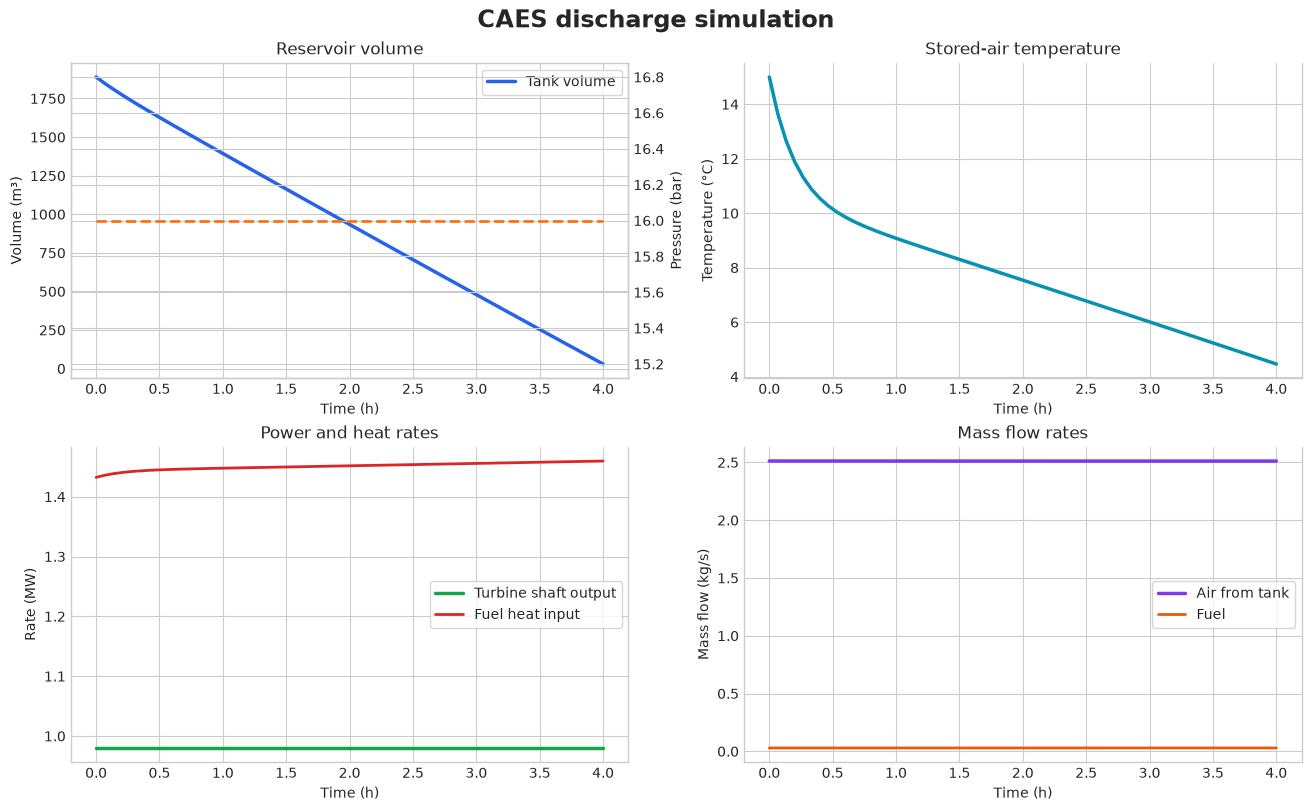

In [139]:
import matplotlib.pyplot as plt

# Extract simulation data
time_s = df["time"].to_numpy()
time_h = time_s / 3600

air_flow = df["Tank.fluid.out.mdot"].abs().to_numpy()
fuel_flow = df["Fuel_in.port.mdot"].abs().to_numpy()
shaft_power = (Eta_Mech * df["Turbine.Wdot"]).to_numpy()
fuel_heat_rate = df["Comb.Qdot_fuel"].to_numpy()

# Integrate rates over the simulated discharge
turbine_energy_J = np.trapezoid(shaft_power, time_s)
fuel_energy_J = np.trapezoid(fuel_heat_rate, time_s)
air_mass_kg = np.trapezoid(air_flow, time_s)
fuel_mass_kg = np.trapezoid(fuel_flow, time_s)

volume = df["Tank.V"].to_numpy()
tank_temp_C = df["Tank.fluid.T"].to_numpy() - 273.15
tank_pressure_bar = df["Tank.fluid.out.p"].to_numpy() / 1e5

print("Discharge results (provisional Part 5 answers)")
print(f"1. Discharge duration:             {time_h[-1]:.2f} h")
print(f"2. Mean turbine shaft output:      {turbine_energy_J / (time_s[-1] - time_s[0]) / 1e6:.3f} MW")
print(f"3. Turbine shaft energy delivered: {turbine_energy_J / 3.6e9:.3f} MWh")
print(f"4. Fuel heat supplied:             {fuel_energy_J / 1e9:.3f} GJ")
print(f"5. Fuel electrical-equivalent:     {Eta_Fuel * fuel_energy_J / 3.6e9:.3f} MWh")
print(f"6. Air discharged:                 {air_mass_kg:,.0f} kg")
print(f"7. Fuel consumed:                  {fuel_mass_kg:,.1f} kg")
print(f"8. Tank volume:                    {volume[0]:,.1f} → {volume[-1]:,.1f} m³")
print(f"9. Tank pressure range:            {tank_pressure_bar.min():.2f}–{tank_pressure_bar.max():.2f} bar")
print(f"10. Tank air temperature range:    {tank_temp_C.min():.1f}–{tank_temp_C.max():.1f} °C")
print("Note: Round-trip efficiency requires compressor energy from the charge simulation.")

# Plot simulation trends
plt.style.use("seaborn-v0_8-whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(13, 8), constrained_layout=True)
fig.suptitle("CAES discharge simulation", fontsize=17, fontweight="bold")

ax = axes[0, 0]
ax.plot(time_h, volume, color="#2563eb", linewidth=2.5, label="Tank volume")
ax.set(title="Reservoir volume", xlabel="Time (h)", ylabel="Volume (m³)")
ax2 = ax.twinx()
ax2.plot(time_h, tank_pressure_bar, color="#f97316", linewidth=2, linestyle="--", label="Pressure")
ax2.set_ylabel("Pressure (bar)")
ax.legend(loc="best", frameon=True)

ax = axes[0, 1]
ax.plot(time_h, tank_temp_C, color="#0891b2", linewidth=2.5)
ax.set(title="Stored-air temperature", xlabel="Time (h)", ylabel="Temperature (°C)")

ax = axes[1, 0]
ax.plot(time_h, shaft_power / 1e6, color="#16a34a", linewidth=2.5, label="Turbine shaft output")
ax.plot(time_h, fuel_heat_rate / 1e6, color="#dc2626", linewidth=2, label="Fuel heat input")
ax.set(title="Power and heat rates", xlabel="Time (h)", ylabel="Rate (MW)")
ax.legend(frameon=True)

ax = axes[1, 1]
ax.plot(time_h, air_flow, color="#7c3aed", linewidth=2.5, label="Air from tank")
ax.plot(time_h, fuel_flow, color="#ea580c", linewidth=2, label="Fuel")
ax.set(title="Mass flow rates", xlabel="Time (h)", ylabel="Mass flow (kg/s)")
ax.legend(frameon=True)

for ax in axes.flat:
    ax.spines["top"].set_visible(False)

plt.show()

In [140]:
#sys_.structure()
Tank.describe()

=== TankConstP('Tank') ===
  ports (p [bar], mdot [kg/s], T [°C]):
  outputs:
    Q                = 198157
    T_fluid          = 277.614
    T_wall           = 282.441
    V                = 29.6914
=== ControlVolumeP('Tank.fluid') ===
  variables:
    M                = 600.878
    U                = 1.92752e+08
    V                = 29.6914
    h                = 399846
  ports (p [bar], mdot [kg/s], T [°C]):
    inl        p=16.000  mdot=+0  h=410.7kJ/kg  T=15.00
    out        p=16.000  mdot=-2.511  h=399.8kJ/kg  T=4.46
  outputs:
    rho              = 20.2375
    T                = 277.614
    x                = 2
    V                = 29.6914
=== ThermalMass('Tank.wall') ===
  variables:
    T                = 282.441
  ports (p [bar], mdot [kg/s], T [°C]):
  outputs:
    Qdot_ext         = -198157


{'variables': {},
 'ports': {},
 'outputs': {'Q': np.float64(198157.37134245655),
  'T_fluid': 277.6138043757028,
  'T_wall': 282.44104087061936,
  'V': 29.69140105634353}}

In [141]:
Comb.describe()

Turbine.describe()

Exhaust.describe()

=== CombustionChamber('Comb') ===
  ports (p [bar], mdot [kg/s], T [°C]):
    air_in     p=16.000  mdot=+2.511  h=399.8kJ/kg  T=4.46
    fuel_in    p=1.013  mdot=+0.02919  h=887.7kJ/kg  T=15.00
    gas_out    p=15.360  mdot=-2.54  h=974.4kJ/kg  T=550.00
  outputs:
    Qdot_fuel        = 1.4596e+06
    Qdot_released    = 1.4596e+06
    AFR              = 86.0238
    excess_air       = 5.00139
=== Turbine('Turbine') ===
  ports (p [bar], mdot [kg/s], T [°C]):
    inl        p=15.360  mdot=+2.54  h=974.4kJ/kg  T=550.00
    out        p=1.013  mdot=-2.54  h=572.8kJ/kg  T=171.59
  outputs:
    Wdot             = 1e+06
    Wdot_is          = 1.13636e+06
    pressure_ratio   = 15.1629
    h_out_s          = 517981
    T_out_s          = 390.852
=== FluidBoundary('Exhaust') ===
  ports (p [bar], mdot [kg/s], T [°C]):
    port       p=1.013  mdot=+2.54  h=572.8kJ/kg  T=171.59


{'variables': {},
 'ports': {'port': {'p': 101300.0,
   'mdot': 2.5403929977988047,
   'h': 572755.1082475686}},
 'outputs': {}}